### Model Complexity and Evaluation



In [35]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

### Polynomial Models

Thus far, our regression models have taken the form:

$$y = \beta_0 + \beta_1x_1 + \beta_2x_2 + ... + \beta_ix_i$$

where all our inputs to the model were linear.  


In this notebook, we consider models of the form:

$$y = \beta_0 + \beta_1x_1 + \beta_2x_1^2 + ... + \beta_ix_1^i$$

These are commonly referred to as *Polynomial Regression Models* -- however we are still using Linear Regression because the unknown quantities -- $\beta$ -- are linear.

In [36]:
#load in the cars data
cars = pd.read_csv('https://raw.githubusercontent.com/jfkoehler/nyu_bootcamp_fa25/main/data/mtcars.csv')

In [37]:
cars.head(2)

,Unnamed: 0,mpg,cyl,disp,hp,drat,wt,qsec,vs,am,gear,carb
0,Mazda RX4,21.0,6,160.0,110,3.9,2.620,16.46,0,1,4,4
1,Mazda RX4 Wag,21.0,6,160.0,110,3.9,2.875,17.02,0,1,4,4


In [38]:
#x = mpg and y = hp
X = cars[['mpg']]
y = cars['hp']

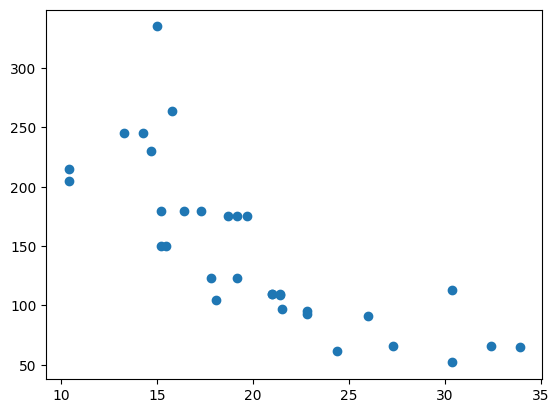

In [39]:
#scatter plot of x vs. y
plt.scatter(X, y)

### Reminder on Least Squares

$$MSE(m, b) = \frac{1}{n}\sum_{i = 1}^n (y_i - (mx_i + b))^2$$

**Assumptions of the model**

- The relationship between features and target are linear in nature
- The features are independent of one another
- The errors are normally distributed
- The residuals have constant variance across all feature values

In [70]:
#baseline for comparison
baseline = np.ones(len(y))*y.mean()

In [71]:
mean_squared_error(y, baseline)

0.42919172641044157

In [40]:
#fit model
lr = LinearRegression()
lr.fit(X, y)
preds = lr.predict(X)

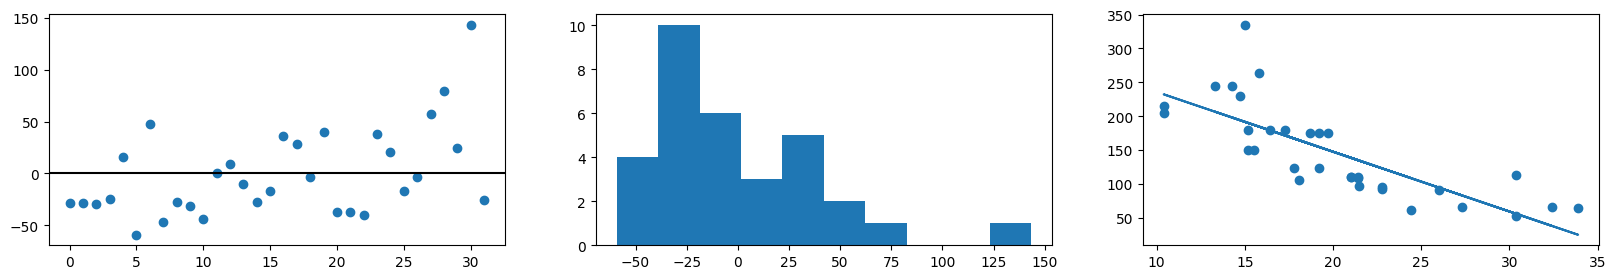

In [41]:
#plot residuals
resids = (y - preds)

fig, ax = plt.subplots(1, 3, figsize = (20, 3))

ax[0].plot(resids, 'o')
ax[0].axhline(color = 'black')
ax[1].hist(resids)
ax[2].scatter(X['mpg'], y)
ax[2].plot(X['mpg'], lr.predict(X))

In [42]:
#Any assumptions violated?  Why?

### Reminder: Quadratics

$$f(x) = ax^2 + bx + c$$


$$f(a, b, c) = \frac{1}{n}\sum_{i = 1}^n (y_i - (ax_i^2 + bx_i + c))^2$$

In plain language, we add a new feature to represent the quadratic term and fit a linear regressor to these columns, essentially what we've done with multiple regression.

In [43]:
#examine X
X.head()

,mpg
0,21.0
1,21.0
2,22.8
3,21.4
4,18.7


In [44]:
#add new feature
X['mpg^2'] = X['mpg']**2

/var/folders/8v/7bhy8yqn04b7rzqglb2s38200000gn/T/ipykernel_7496/1230039856.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  X['mpg^2'] = X['mpg']**2


In [45]:
# check X again
X.head(2)

,mpg,mpg^2
0,21.0,441.0
1,21.0,441.0


In [46]:
#fit model and look at coefficients
model1 = LinearRegression().fit(X, y)
model1.coef_

array([-23.34451763,   0.33002884])

In [47]:
# intercept
model1.intercept_

470.86947158376057

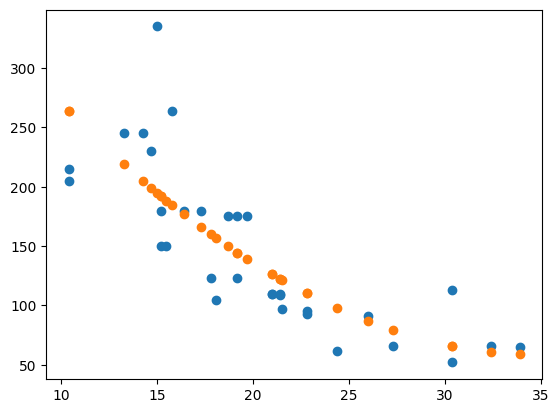

In [48]:
plt.scatter(X['mpg'], y)
plt.scatter(X['mpg'], model1.predict(X))

In [49]:
# mean squared error?
mean_squared_error(y, model1.predict(X))

1623.1102840474189

**QUESTION**: Which is better -- the first or second degree model?

### Problem

1. Add a cubic term to the data.  
2. Fit a new model to the cubic data.
3. Determine the `mean_squared_error` of the linear, quadratic, and cubic models.  How do they compare?
4. Would a quartic polynomial (4th degree) be better or worse in terms of `mean_squared_error`?


### Experimenting with complexity

Below, a synthetic dataset is created and different complexity regression models can be controlled using the slider.  Which degree complexity seems best?  Consider the new data after you determine the ideal model.

In [50]:
from ipywidgets import interact
import ipywidgets as widgets

In [51]:
def true_fun(X):
    return np.cos(1.5 * np.pi * X)
np.random.seed(0)
n_samples = 30
X = np.sort(np.random.rand(n_samples))
y = true_fun(X) + np.random.randn(n_samples) * 0.1

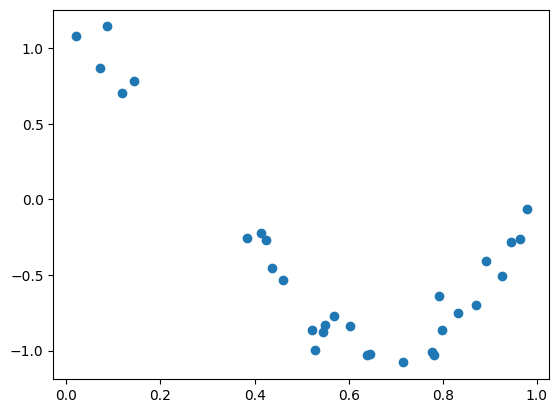

In [52]:
plt.scatter(X, y);

In [53]:
# Don't Peek!
# x = np.random.choice(x, 50, replace = False)
def model_maker(n):
    coefs = np.polyfit(X, y, n)
    preds = np.polyval(coefs, X)
    x_,y_,p_ = zip(*sorted(zip(X, y, preds)))
    plt.scatter(x_, y_, label = 'Known Data')
    plt.plot(x_, p_, color = 'red')
    plt.title(f'Degree {n}')
    plt.legend();

In [54]:
interact(model_maker, n = widgets.IntSlider(start = 1, min = 1, max = len(y), step = 1));

interactive(children=(IntSlider(value=1, description='n', max=30, min=1), Output()), _dom_classes=('widget-int…

In [55]:
#CHOOSE OPTIMAL COMPLEXITY

`PolynomialFeatures`

Scikitlearn has a transformer that will do the work of adding polynomial terms on to our dataset.  For more information see the documentation [here](https://scikit-learn.org/stable/modules/preprocessing.html#polynomial-features).

In [56]:
from sklearn.preprocessing import PolynomialFeatures

Now, let's use `PolynomialFeatures` to solve the earlier problem predicting `hp` using `mpg`. 

In [59]:
X = cars[['mpg']]

In [60]:
#instantiate polynomial features
pfeats = PolynomialFeatures(include_bias=False)

In [61]:
#transform X
XT = pfeats.fit_transform(X[['mpg']])

In [62]:
XT.shape

(32, 2)

In [63]:
#examine feature names
pfeats.get_feature_names_out()

array(['mpg', 'mpg^2'], dtype=object)

In [65]:
#just so you understand what's happening
pd.DataFrame(XT, columns = pfeats.get_feature_names_out()).head()

,mpg,mpg^2
0,21.0,441.00
1,21.0,441.00
2,22.8,519.84
3,21.4,457.96
4,18.7,349.69


In [ ]:
#instantiate model
lr5 = LinearRegression().fit(XT, cars['hp'])

In [ ]:
#fit, predict and score
mean_squared_error(cars['hp'], lr5.predict(XT))

#### `train_test_split`



To this point, we have evaluated our models using the data they were built with.  If our goal is to use these models for future predictions, it would be better to understand the performance on data the model has *not* seen in the past.  To mimic this notion of unseen data, we create a small holdout set of data to use in evaluation.  

- **Train Data**: Data to build our model with.
- **Test Data**: Data to evaluate the model with (usually a smaller dataset than train)

Scikitlearn has a `train_test_split` function that will create these datasets for us.  Below we load it from the `model_selection` module and explore its functionality. [User Guide](https://scikit-learn.org/stable/modules/cross_validation.html#cross-validation)

In [73]:
# import function
from sklearn.model_selection import train_test_split

In [74]:
# create a train and test split
y = cars['hp']
X_train, X_test, y_train, y_test = train_test_split(XT, y, random_state=42)

In [75]:
# explore train data
X_train.shape

(24, 2)

In [76]:
# explore test data
X_test.shape

(8, 2)

In [77]:
# build model with train
lr = LinearRegression()
lr.fit(X_train, y_train)

LinearRegression()

In [78]:
# evaluate train mse
train_preds = lr.predict(X_train) 
print(mean_squared_error(y_train, train_preds))

1076.664148967975


In [79]:
# evaluate test mse
test_preds = lr.predict(X_test)
print(mean_squared_error(y_test, test_preds))

3424.62590870615


#### Using the test data to determine model complexity

Now, you can use the test set to measure the performance of models with varied complexity -- choosing the "best" based on the scores on the test data.

In [80]:
# create polynomial features for train and test
for i in range(1, 10):
    poly_feats = PolynomialFeatures(degree = i, include_bias = False)
    X_train_poly = poly_feats.fit_transform(X_train)
    X_test_poly = poly_feats.transform(X_test)
    lr = LinearRegression()
    lr.fit(X_train_poly, y_train)
    train_preds = lr.predict(X_train_poly)
    test_preds = lr.predict(X_test_poly)
    print(f'Train MSE: {mean_squared_error(y_train, train_preds)}')
    print(f'Test MSE: {mean_squared_error(y_test, test_preds)}')
    print('--------------------------------')


Train MSE: 1076.664148967975
Test MSE: 3424.62590870615
--------------------------------
Train MSE: 819.6896362278408
Test MSE: 2740.5076094450405
--------------------------------
Train MSE: 779.1116137946063
Test MSE: 2783.3566973521306
--------------------------------
Train MSE: 757.0893108145816
Test MSE: 3493.6718997265625
--------------------------------
Train MSE: 750.5233233919222
Test MSE: 12821.629881401424
--------------------------------
Train MSE: 757.0737985148033
Test MSE: 76165.11071392534
--------------------------------
Train MSE: 775.4900345505683
Test MSE: 450722.28290456336
--------------------------------
Train MSE: 797.4142544345755
Test MSE: 2529984.0308952453
--------------------------------
Train MSE: 814.1223225548125
Test MSE: 9191706.393489875
--------------------------------


### Part II

#### Another Example

Below a dataset about neighborhoods houses are loaded from `scikitlearn`.  Your goal is to:

- Determine the RMSE of a naive model that only guesses the mean of `y` (`MedHouseVal`).
- Build a regression model with features you believe would be good predictors
- Incorporate `PolynomialFeatures` and see if a quadratic model performs better
- Explore the documentation for `GridSearchCV` [here](https://scikit-learn.org/stable/modules/grid_search.html#grid-search).  Use it to search for the ideal model complexity.

Build your models on a **train** set and evaluate them on the **test** set.  Record your findings [here](https://forms.gle/vRW4MTxAWH6ixoNu8).

In [81]:
from sklearn.datasets import fetch_california_housing

In [82]:
data = fetch_california_housing(as_frame=True)
housing = data.frame
housing.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [72]:
X = ''
y = ''

In [87]:
#baseline rmse


In [83]:
#X_train, X_test, y_train, y_test = train_test_split()

In [84]:
#model 1 -- linear

In [85]:
#model 2 -- quadratic

In [86]:
#if time use GridSearch

### Splines 

In [88]:
from sklearn.preprocessing import SplineTransformer
from sklearn.pipeline import Pipeline

In [89]:
from sklearn.linear_model import LinearRegression

In [99]:
def f(x): return 2 + 3*np.sin(2*x) + np.random.normal(size = len(x))

In [100]:
x = np.linspace(0, 4, 100)

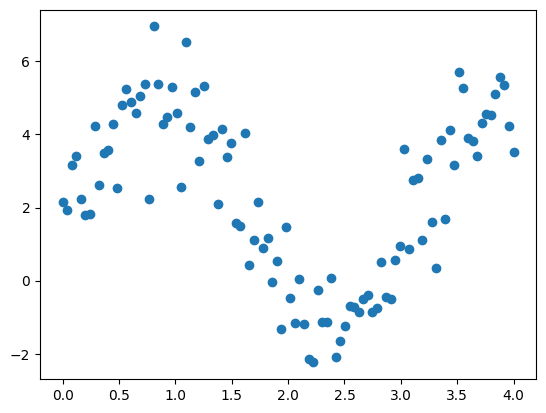

In [101]:
plt.scatter(x, f(x));

In [102]:
pipe = Pipeline([('spline', SplineTransformer()), ('model', LinearRegression())])

In [104]:
pipe.fit(x.reshape(-1, 1), f(x))

Pipeline(steps=[('spline', SplineTransformer()), ('model', LinearRegression())])

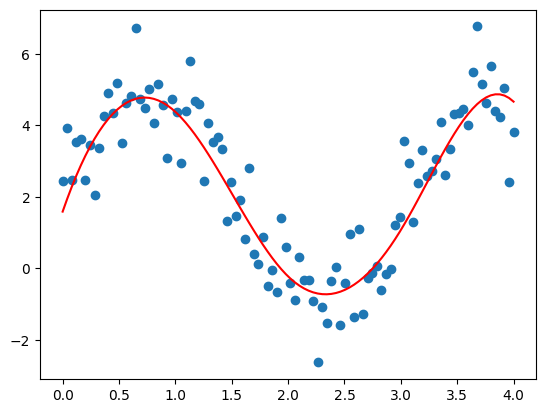

In [108]:
plt.scatter(x, f(x));
plt.plot(x, pipe.predict(x.reshape(-1,1)), '-r');